In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [4]:
df=pd.read_csv(r'C:/Users/World/Downloads/Compressed/adult.csv')
df

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [5]:
df.shape

(48842, 15)

In [6]:
df.info()
# df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [7]:
df.select_dtypes(include=['object','category']).columns.to_frame().reset_index()[0]

0         workclass
1         education
2    marital-status
3        occupation
4      relationship
5              race
6            gender
7    native-country
8            income
Name: 0, dtype: object

In [8]:
 df.nunique()

age                   74
workclass              9
fnlwgt             28523
education             16
educational-num       16
marital-status         7
occupation            15
relationship           6
race                   5
gender                 2
capital-gain         123
capital-loss          99
hours-per-week        96
native-country        42
income                 2
dtype: int64

In [9]:
less=df.loc[df['income']=='<=50K',['income']]
greater=df.loc[df['income']=='>50K',['income']]

print(f'income<=50K :{len(less)} and income>50K : {len(greater)}')


income<=50K :37155 and income>50K : 11687


In [10]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


<Axes: xlabel='age', ylabel='Count'>

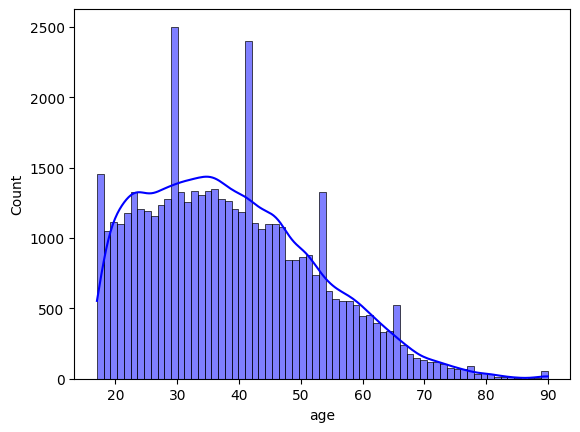

In [11]:
sns.histplot(df['age'], kde=True,color='blue')

<Axes: xlabel='hours-per-week', ylabel='Count'>

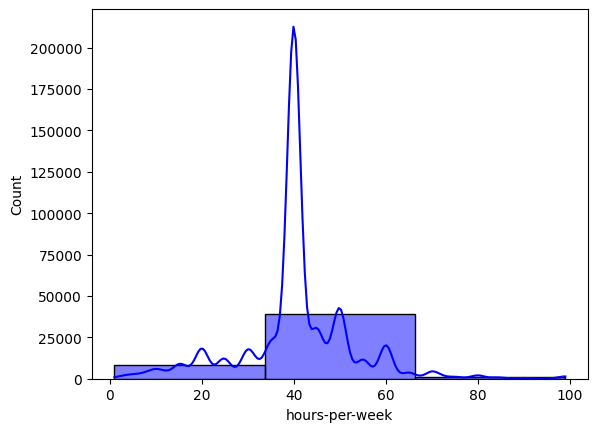

In [12]:
sns.histplot(df['hours-per-week'], kde=True,color='blue',binwidth=30)


Number of extreme values: 0


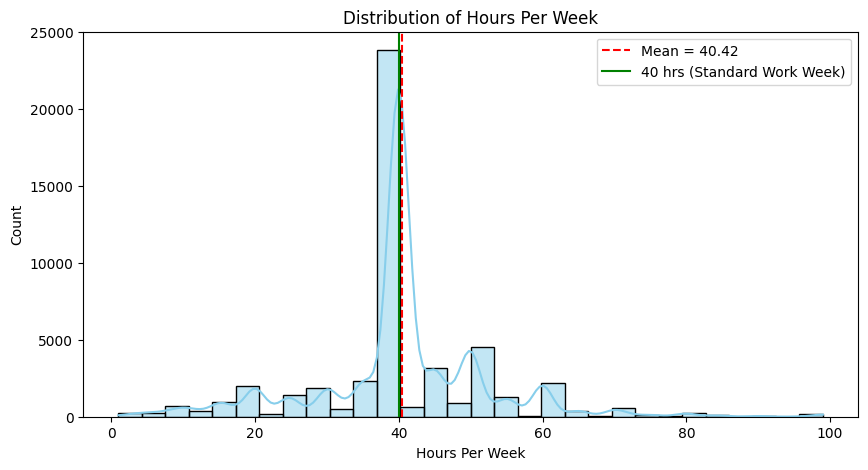

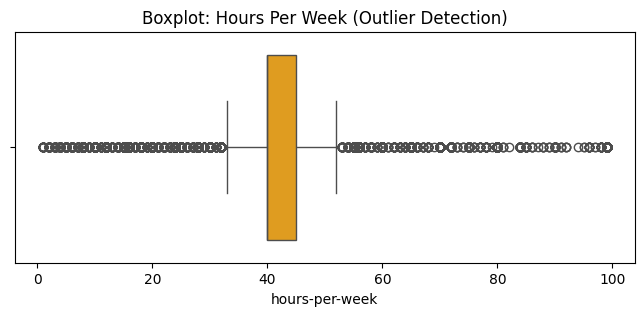

In [13]:
# --- 2. Check for extreme values (0 or > 100 hours) ---
extreme_values = df[(df['hours-per-week'] <= 0) | (df['hours-per-week'] > 100)]
print(f"\nNumber of extreme values: {extreme_values.shape[0]}")
if not extreme_values.empty:
    print(extreme_values['hours-per-week'].value_counts())

# --- 3. Visualize Distribution ---
plt.figure(figsize=(10,5))
sns.histplot(df['hours-per-week'], bins=30, kde=True, color='skyblue')
plt.axvline(df['hours-per-week'].mean(), color='red', linestyle='--', label=f"Mean = {df['hours-per-week'].mean():.2f}")
plt.axvline(40, color='green', linestyle='-', label="40 hrs (Standard Work Week)")
plt.title("Distribution of Hours Per Week")
plt.xlabel("Hours Per Week")
plt.ylabel("Count")
plt.legend()
plt.show()

# --- 4. Boxplot to Spot Outliers ---
plt.figure(figsize=(8,3))
sns.boxplot(x=df['hours-per-week'], color="orange")
plt.title("Boxplot: Hours Per Week (Outlier Detection)")
plt.show()

In [14]:
df.groupby('capital-gain').max().sort_values(by='capital-gain',ascending=False).head(1)
# print(df[df['capital-gain'] == df['capital-gain'].max()])

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-loss,hours-per-week,native-country,income
capital-gain,,,,,,,,,,,,,,
99999,80,State-gov,553405,Some-college,16,Widowed,Transport-moving,Wife,White,Male,0,99,United-States,>50K


In [15]:
df.groupby('capital-loss').max().sort_values(by='capital-loss',ascending=False).head(1)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,hours-per-week,native-country,income
capital-loss,,,,,,,,,,,,,,
4356,90,Private,186061,Some-college,10,Widowed,Exec-managerial,Unmarried,White,Female,0,40,United-States,<=50K


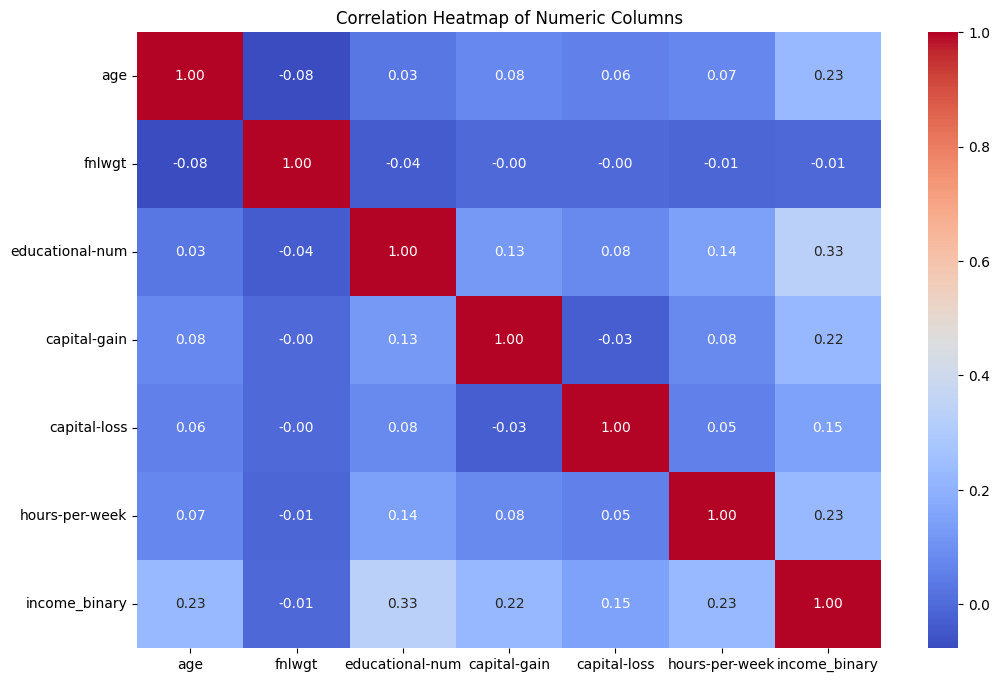

In [16]:
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)

# Select numeric columns only
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numeric Columns")
plt.show()

In [17]:
df['workclass'].value_counts(dropna=False)

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

education
HS-grad    15784
Name: count, dtype: int64


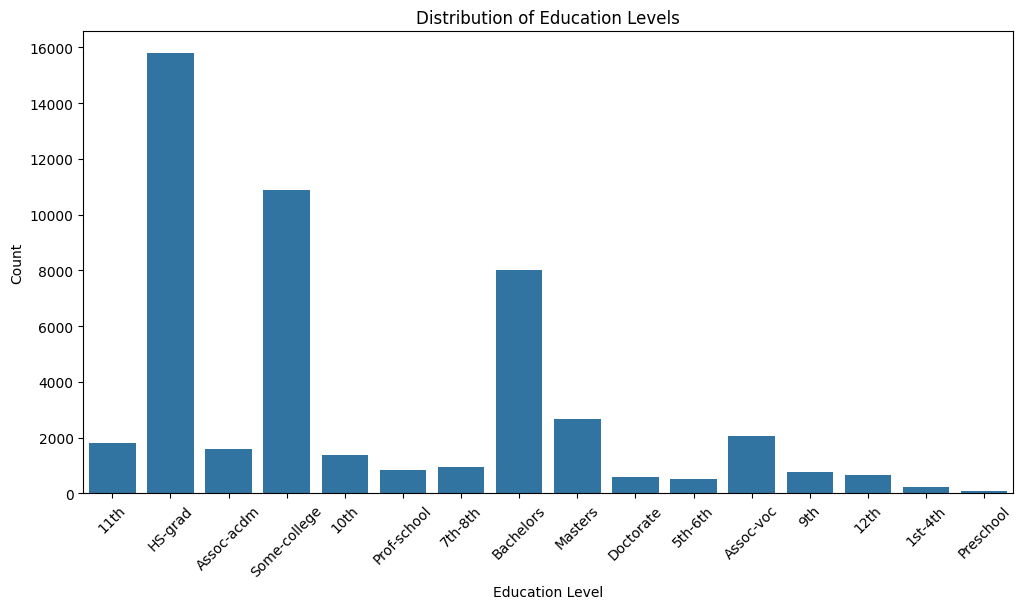

In [18]:
mustCommon=df['education'].value_counts().head(1)
print(mustCommon)
plt.figure(figsize=(12,6))
sns.countplot(x='education', data=df, )
plt.xticks(rotation=45)  # Rotate labels so they don't overlap
plt.title("Distribution of Education Levels")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.show()

In [19]:
edu_check = df.groupby("education")["educational-num"].unique().sort_values()

print(len(edu_check), "==", len(df["education"].unique()))


16 == 16


occupation
Prof-specialty       6172
Craft-repair         6112
Exec-managerial      6086
Adm-clerical         5611
Sales                5504
Other-service        4923
Machine-op-inspct    3022
?                    2809
Transport-moving     2355
Handlers-cleaners    2072
Farming-fishing      1490
Tech-support         1446
Protective-serv       983
Priv-house-serv       242
Armed-Forces           15
Name: count, dtype: int64

most common occupation
Prof-specialty    6172
Name: count, dtype: int64


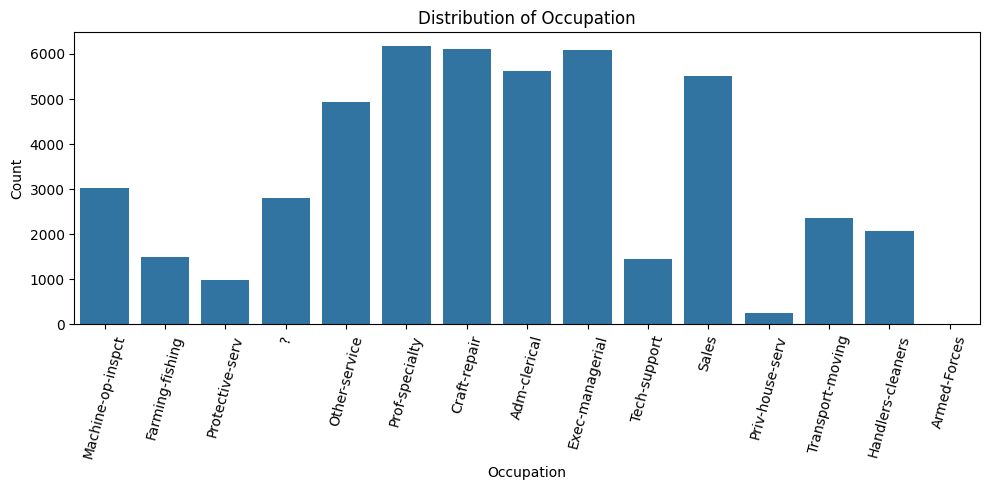

In [20]:
# Show counts of all unique occupations
print(df['occupation'].value_counts())

print('\nmost common',df['occupation'].value_counts().head(1))
plt.figure(figsize=(10, 5))
sns.countplot(x='occupation', data=df, )
plt.xticks(rotation=75)
plt.title("Distribution of Occupation")
plt.xlabel("Occupation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

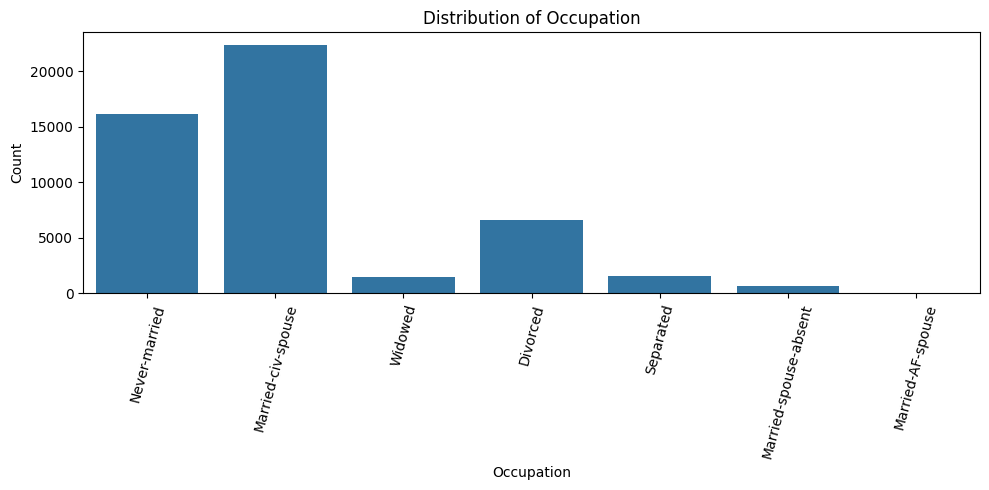

In [21]:

plt.figure(figsize=(10, 5))
sns.countplot(x='marital-status', data=df, )
plt.xticks(rotation=75)
plt.title("Distribution of Occupation")
plt.xlabel("Occupation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [22]:
df['gender']

0          Male
1          Male
2          Male
3          Male
4        Female
          ...  
48837    Female
48838      Male
48839    Female
48840      Male
48841    Female
Name: gender, Length: 48842, dtype: object

C:\Users\World\AppData\Local\Temp\ipykernel_4776\2608873413.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette="pastel")


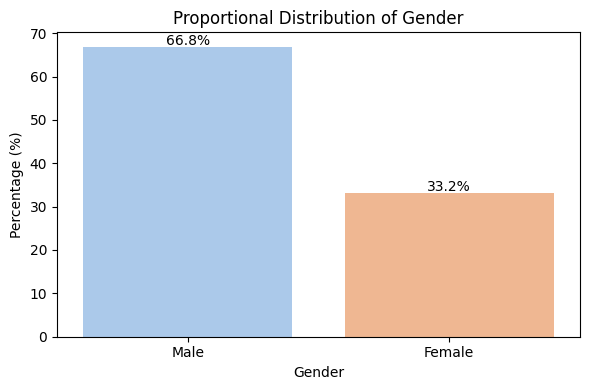

In [23]:
counts = df['gender'].value_counts(normalize=True) * 100  # percentages

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette="pastel")

# Add percentage labels above bars
for i, val in enumerate(counts.values):
    plt.text(i, val + 0.5, f"{val:.1f}%", ha='center', fontsize=10)

plt.title("Proportional Distribution of Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

race
White                 41762
Black                  4685
Asian-Pac-Islander     1519
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64


C:\Users\World\AppData\Local\Temp\ipykernel_4776\2923353553.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='race', data=df, order=counts.index, palette='Set2')


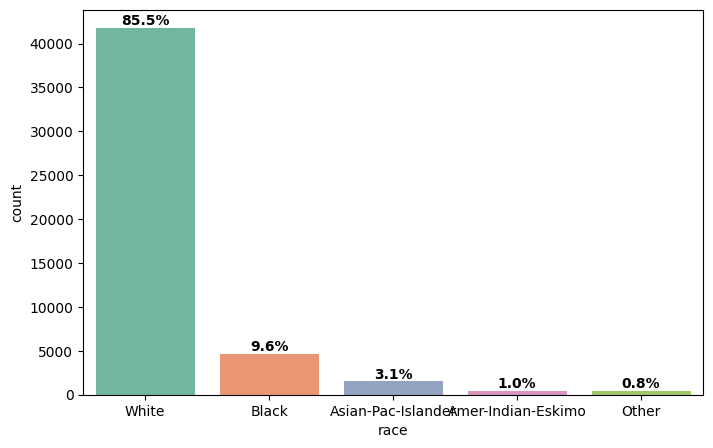

In [26]:
print(df['race'].value_counts())
counts = df['race'].value_counts()
total = len(df)

plt.figure(figsize=(8, 5))
ax = sns.countplot(x='race', data=df, order=counts.index, palette='Set2')

# Add percentages on top of bars
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%'
    ax.annotate(percentage,
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')


In [27]:
print(df['native-country'].value_counts())
print('\n Most frequently',df['native-country'].value_counts().head(1))


native-country
United-States                 43832
Mexico                          951
?                               857
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Guatemala                        88
Poland                           87
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Greece                           49
Nicaragua                        49
Peru         

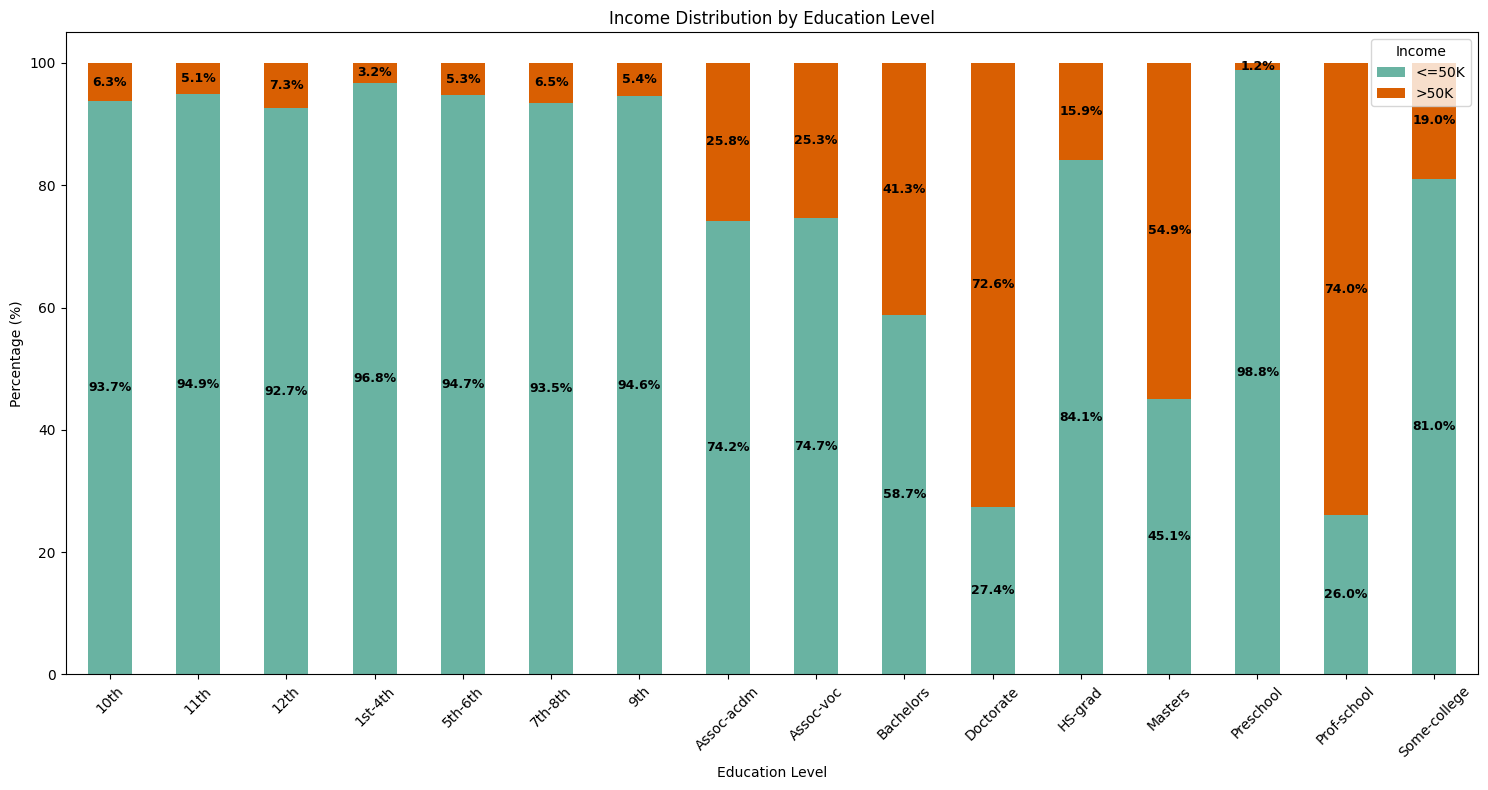

In [38]:
edu_income_percent = pd.crosstab(df["education"], df["income"], normalize="index") * 100

# Plot directly
ax=edu_income_percent.plot(kind="bar", stacked=True, figsize=(15, 8), color=["#69b3a2", "#d95f02"])

plt.title("Income Distribution by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Percentage (%)")
plt.legend(title="Income")
plt.xticks(rotation=45)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",        # format as percentage
        label_type="center", # place inside bar
        fontsize=9,
        color="black",
        fontweight="bold"    # makes it more readable
    )
plt.tight_layout()
plt.show()

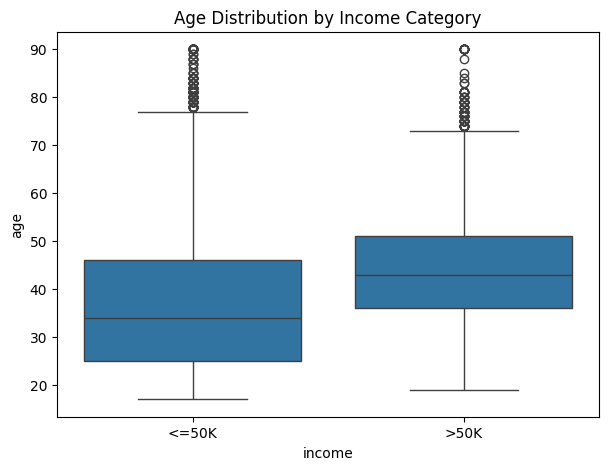

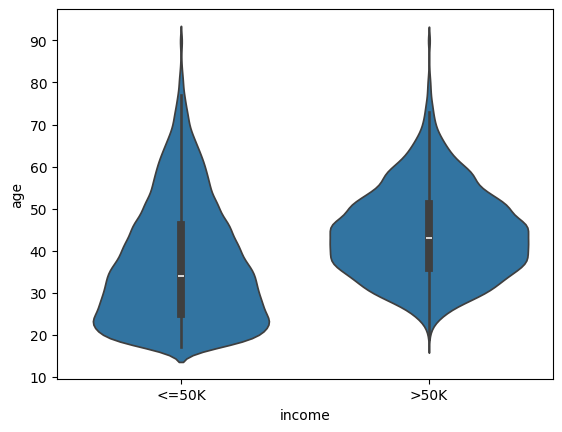

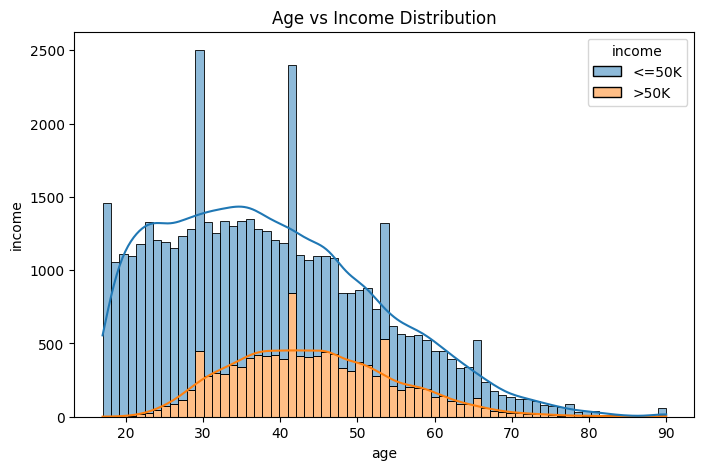

In [39]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="income", y="age", data=df)
plt.title("Age Distribution by Income Category")
plt.show()
sns.violinplot(x="income", y="age", data=df)
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", hue="income", kde=True, multiple="stack")
plt.title("Age vs Income Distribution")
plt.ylabel('income')
plt.show()


In [40]:
age_bins = pd.cut(df["age"], bins=[15,25,35,45,55,65,90])
pd.crosstab(age_bins, df["income"], normalize="index") * 100

income,<=50K,>50K
age,,
"(15, 25]",98.244521,1.755479
"(25, 35]",81.295699,18.704301
"(35, 45]",65.436747,34.563253
"(45, 55]",60.764224,39.235776
"(55, 65]",68.593926,31.406074
"(65, 90]",80.199667,19.800333


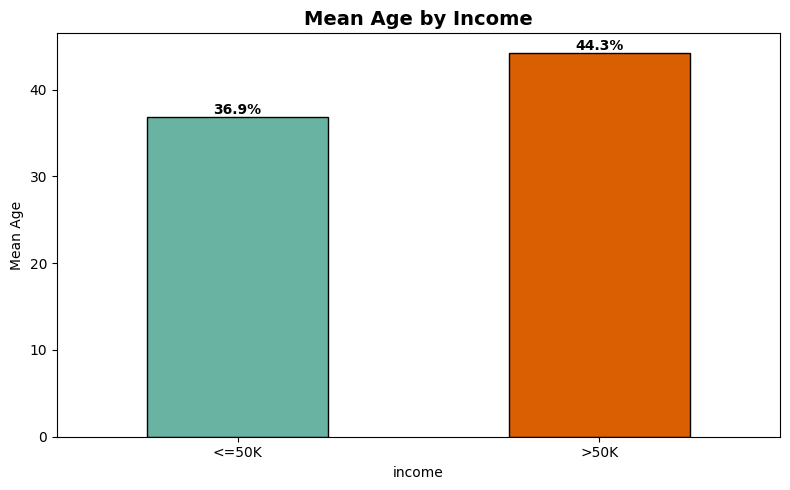

In [47]:
ax = df.groupby("income")["age"].mean().plot(
    kind="bar",
    color=["#69b3a2", "#d95f02"],
    figsize=(8, 5),
    edgecolor="black"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="edge", fontsize=10, fontweight="bold")

plt.title("Mean Age by Income", fontsize=14, fontweight="bold")
plt.ylabel("Mean Age")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



In [48]:
df.groupby('occupation')['income'].value_counts().to_frame()

count
occupation        income       
?                 <=50K    2544
                  >50K      265
Adm-clerical      <=50K    4843
                  >50K      768
Armed-Forces      <=50K      10
                  >50K        5
Craft-repair      <=50K    4729
                  >50K     1383
Exec-managerial   <=50K    3178
                  >50K     2908
Farming-fishing   <=50K    1317
                  >50K      173
Handlers-cleaners <=50K    1934
                  >50K      138
Machine-op-inspct <=50K    2650
                  >50K      372
Other-service     <=50K    4719
                  >50K      204
Priv-house-serv   <=50K     239
                  >50K        3
Prof-specialty    <=50K    3388
                  >50K     2784
Protective-serv   <=50K     675
                  >50K      308
Sales             <=50K    4029
                  >50K     1475
Tech-support      <=50K    1026
                  >50K      420
Transport-moving  <=50K    1874
                  >50K      481

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

# Crosstab to see percentage of people earning <=50K vs >50K in each occupation
occupation_income = pd.crosstab(df["occupation"], df["income"], normalize="index") * 100

# Sort by >50K percentage
occupation_income_sorted = occupation_income.sort_values(by=">50K", ascending=False)

print(occupation_income_sorted)


income                 <=50K       >50K
occupation                             
Exec-managerial    52.218206  47.781794
Prof-specialty     54.893065  45.106935
Armed-Forces       66.666667  33.333333
Protective-serv    68.667345  31.332655
Tech-support       70.954357  29.045643
Sales              73.201308  26.798692
Craft-repair       77.372382  22.627618
Transport-moving   79.575372  20.424628
Adm-clerical       86.312600  13.687400
Machine-op-inspct  87.690271  12.309729
Farming-fishing    88.389262  11.610738
?                  90.566038   9.433962
Handlers-cleaners  93.339768   6.660232
Other-service      95.856185   4.143815
Priv-house-serv    98.760331   1.239669


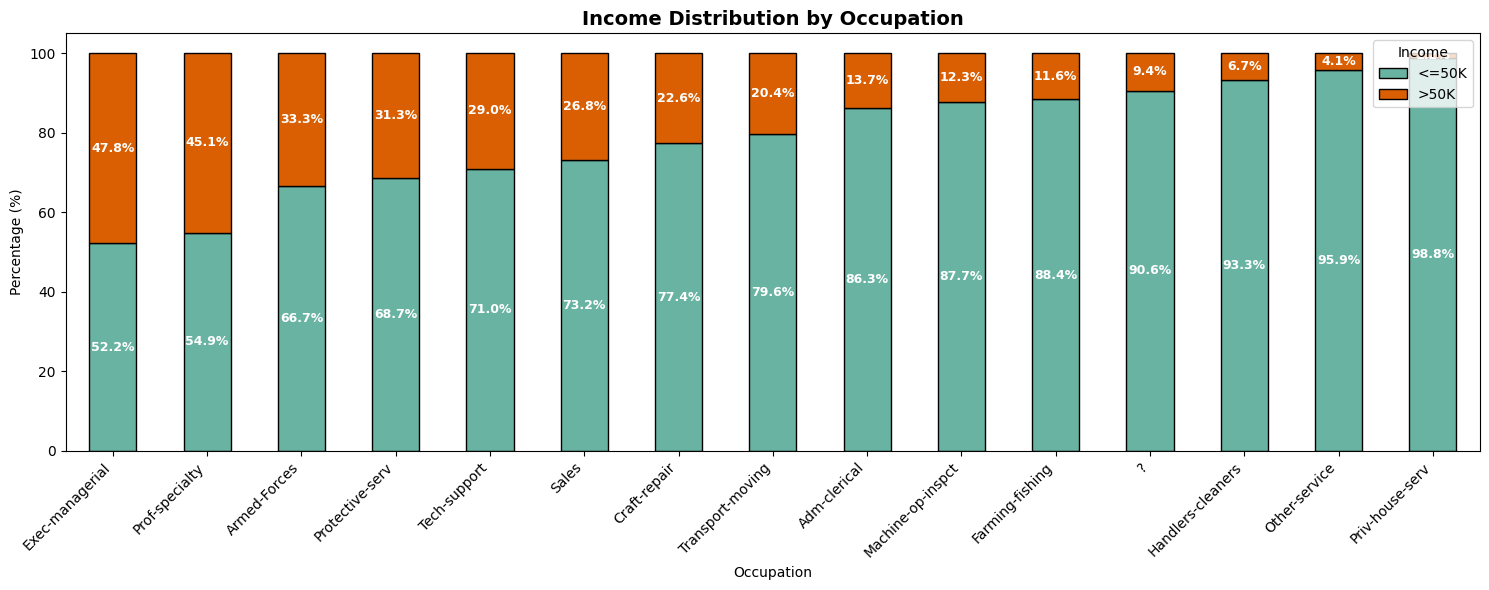

In [55]:
ax = occupation_income_sorted.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 6),
    color=["#69b3a2", "#d95f02"],
    edgecolor="black"  # optional: adds border for clarity
)

plt.title("Income Distribution by Occupation", fontsize=14, fontweight="bold")
plt.xlabel("Occupation")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income", loc="upper right", fontsize=10)

# --- Add percentage labels inside bars ---
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",        # format as percentage
        label_type="center", # place inside bar
        fontsize=9,
        color="white",
        fontweight="bold"    # makes it more readable
    )

plt.tight_layout()
plt.show()


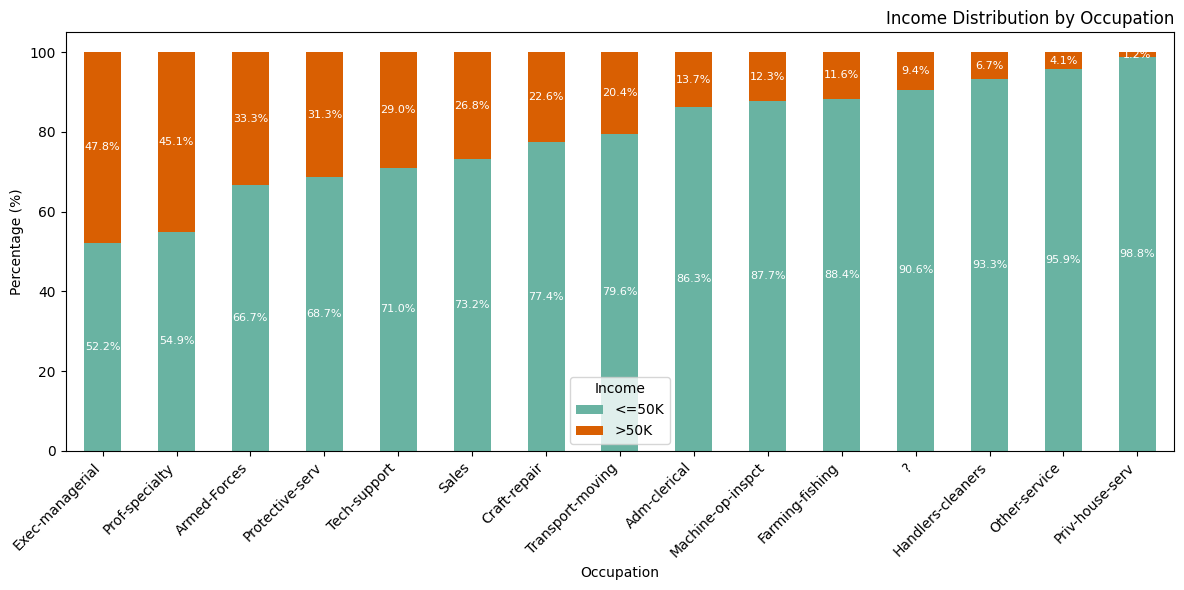

In [59]:
ax = occupation_income_sorted.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["#69b3a2", "#d95f02"]
)

plt.title("Income Distribution by Occupation",loc='right')
plt.xlabel("Occupation")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()

# --- Add percentage labels on bars ---
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', fontsize=8, color='white')

plt.show()